In [11]:
from sklearn.datasets import load_iris
import pandas as pd

# 1. 加载 Iris 数据集
iris = load_iris()

# 2. 提取特征数据
X = iris.data

# 3. 提取分类标签
y = iris.target

# 4. 查看数据集基本信息
print("特征矩阵形状:", X.shape)
print("标签数组形状:", y.shape)
print("特征名称:", iris.feature_names)
print("类别名称:", iris.target_names)

# 5. 转换为 DataFrame，方便查看
df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = y

# 6. 查看前五行
display(df.head())

特征矩阵形状: (150, 4)
标签数组形状: (150,)
特征名称: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
类别名称: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [12]:
# 查看数据集的基本信息
print("========== 数据基本信息 ==========")
df.info()

# 查看数值特征的统计信息
print("\n========== 描述性统计 ==========")
display(df.describe())

# 检查缺失值
print("\n========== 缺失值统计 ==========")
print(df.isnull().sum())

# 统计每个类别的样本数量
print("\n========== 类别分布 ==========")
print(df["species"].value_counts().sort_index())

========== 数据基本信息 ==========
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

========== 描述性统计 ==========


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



========== 缺失值统计 ==========
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

========== 类别分布 ==========
species
0    50
1    50
2    50
Name: count, dtype: int64


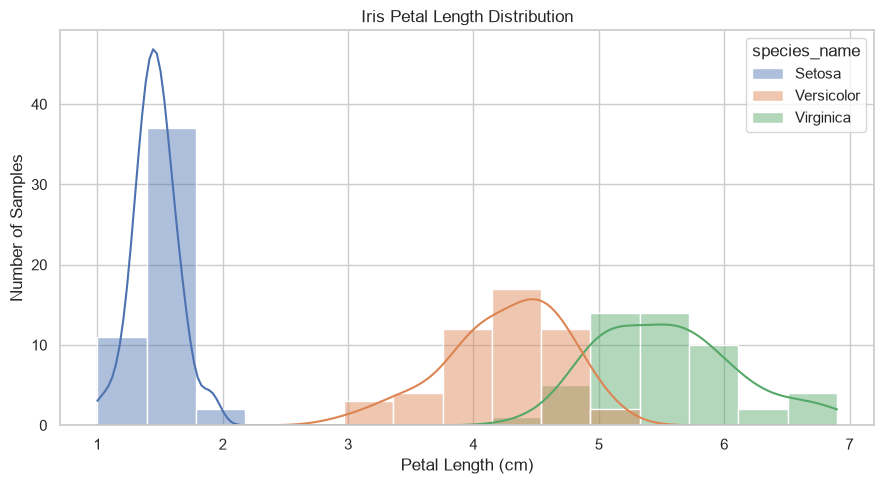

图片保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\01_iris_petal_length_distribution.png


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. 为数据添加可读的花种名称
df["species_name"] = df["species"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})

# 2. 设置绘图风格
sns.set_theme(style="whitegrid")

# 3. 创建图表
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="petal length (cm)",
    hue="species_name",
    bins=15,
    kde=True,
    alpha=0.45
)

# 4. 添加标题和坐标轴标签
plt.title("Iris Petal Length Distribution")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Number of Samples")

plt.tight_layout()

# 5. 保存图片到项目 results/figures 文件夹
project_root = Path(
    r"D:\AI-Internship\Week01_AI_Basic_Iris_Regression"
)
figure_dir = project_root / "results" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "01_iris_petal_length_distribution.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")

# 6. 显示图表
plt.show()

print("图片保存成功！")
print("保存路径：", figure_path)

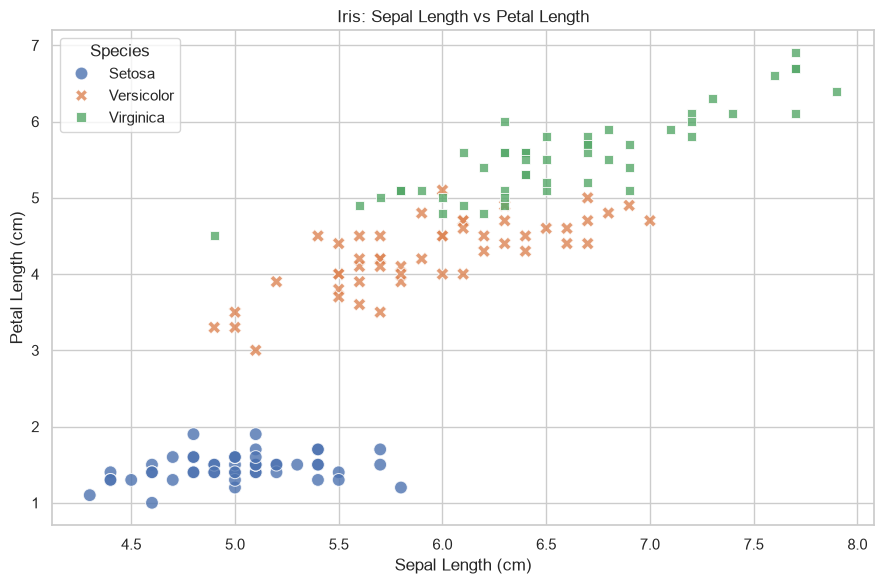

保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\02_iris_sepal_vs_petal_scatter.png


In [14]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="sepal length (cm)",
    y="petal length (cm)",
    hue="species_name",
    style="species_name",
    s=85,
    alpha=0.8
)

plt.title("Iris: Sepal Length vs Petal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.legend(title="Species")

plt.tight_layout()


figure_path = figure_dir / "02_iris_sepal_vs_petal_scatter.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("保存成功！")
print("保存路径：", figure_path)

========== 特征相关系数矩阵 ==========


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.00,-0.12,0.87,0.82
sepal width (cm),-0.12,1.00,-0.43,-0.37
petal length (cm),0.87,-0.43,1.00,0.96
petal width (cm),0.82,-0.37,0.96,1.00


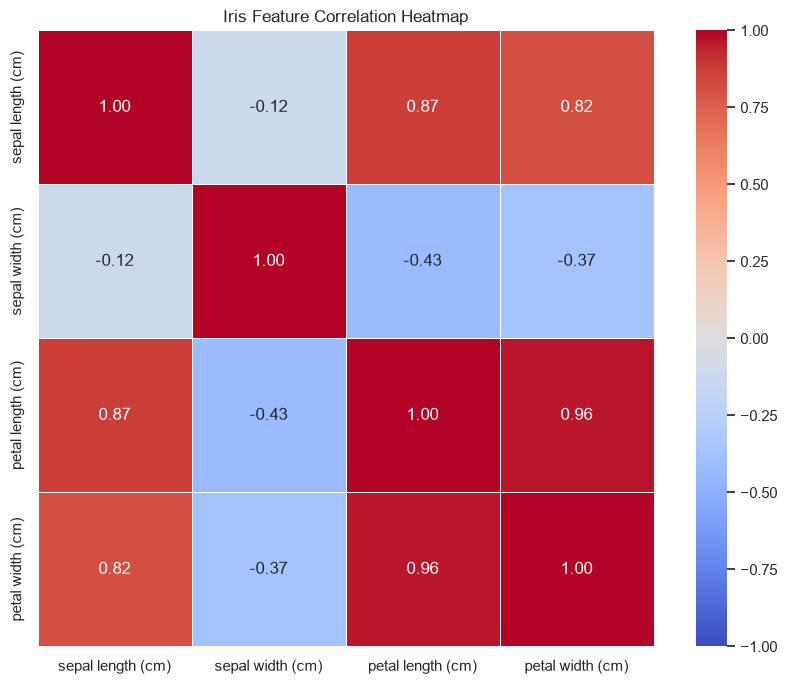

保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\03_iris_correlation_heatmap.png


In [15]:
# 1. 只选择四个数值测量特征
feature_columns = iris.feature_names

# 2. 计算相关系数矩阵
correlation_matrix = df[feature_columns].corr()

# 3. 显示相关系数
print("========== 特征相关系数矩阵 ==========")
display(correlation_matrix.round(2))

# 4. 创建热力图
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Iris Feature Correlation Heatmap")

plt.tight_layout()

# 5. 保存图片
figure_path = figure_dir / "03_iris_correlation_heatmap.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

# 6. 显示图片
plt.show()

print("保存成功！")
print("保存路径：", figure_path)

In [16]:
from sklearn.model_selection import train_test_split

# X：4个测量特征
# y：花的类别标签
X = df[iris.feature_names]
y = df["species"]

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 检查划分结果
print("========== 数据集划分结果 ==========")
print("训练集特征形状:", X_train.shape)
print("测试集特征形状:", X_test.shape)
print("训练集标签形状:", y_train.shape)
print("测试集标签形状:", y_test.shape)

print("\n========== 训练集类别分布 ==========")
print(y_train.value_counts().sort_index())

print("\n========== 测试集类别分布 ==========")
print(y_test.value_counts().sort_index())

========== 数据集划分结果 ==========
训练集特征形状: (120, 4)
测试集特征形状: (30, 4)
训练集标签形状: (120,)
测试集标签形状: (30,)

========== 训练集类别分布 ==========
species
0    40
1    40
2    40
Name: count, dtype: int64

========== 测试集类别分布 ==========
species
0    10
1    10
2    10
Name: count, dtype: int64


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. 创建逻辑回归模型
lr_model = LogisticRegression(max_iter=1000)

# 2. 使用训练集训练模型
lr_model.fit(X_train, y_train)

# 3. 使用测试集进行预测
y_pred_lr = lr_model.predict(X_test)

# 4. 计算分类准确率
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("========== 逻辑回归分类结果 ==========")
print("模型名称：Logistic Regression")
print("训练样本数量：", len(X_train))
print("测试样本数量：", len(X_test))
print(f"分类准确率：{lr_accuracy:.4f}")
print(f"分类准确率（百分比）：{lr_accuracy * 100:.2f}%")

# 5. 查看前10个预测结果
comparison = pd.DataFrame({
    "真实类别": y_test.to_numpy(),
    "预测类别": y_pred_lr
})

print("\n========== 前10个预测结果 ==========")
display(comparison.head(10))

========== 逻辑回归分类结果 ==========
模型名称：Logistic Regression
训练样本数量： 120
测试样本数量： 30
分类准确率：0.9667
分类准确率（百分比）：96.67%

========== 前10个预测结果 ==========


,真实类别,预测类别
0,0,0
1,2,2
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,2,2
9,1,1


KNN

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

# 1. 创建 KNN 模型
# 使用标准化 + KNN 的组合
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# 2. 使用训练集训练模型
knn_model.fit(X_train, y_train)

# 3. 预测测试集
y_pred_knn = knn_model.predict(X_test)

# 4. 计算准确率
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("========== KNN 分类结果 ==========")
print("模型名称: K-Nearest Neighbors")
print("K 值: 5")
print("训练样本数量：", len(X_train))
print("测试样本数量：", len(X_test))
print(f"分类准确率：{knn_accuracy:.4f}")
print(f"分类准确率（百分比）：{knn_accuracy * 100:.2f}%")

# 5. 查看前10个预测结果
knn_comparison = pd.DataFrame({
    "真实类别": y_test.to_numpy(),
    "预测类别": y_pred_knn
})

print("\n========== 前10个预测结果 ==========")
display(knn_comparison.head(10))

# 6. 与逻辑回归进行比较
print("\n========== 模型准确率对比 ==========")
print(f"Logistic Regression: {lr_accuracy * 100:.2f}%")
print(f"KNN: {knn_accuracy * 100:.2f}%")

========== KNN 分类结果 ==========
模型名称: K-Nearest Neighbors
K 值: 5
训练样本数量： 120
测试样本数量： 30
分类准确率：0.9333
分类准确率（百分比）：93.33%

========== 前10个预测结果 ==========


,真实类别,预测类别
0,0,0
1,2,2
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,2,2
9,1,1



========== 模型准确率对比 ==========
Logistic Regression: 96.67%
KNN: 93.33%


DecisionTree

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 1. 创建决策树分类模型
dt_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# 2. 使用训练集训练模型
dt_model.fit(X_train, y_train)

# 3. 使用测试集进行预测
y_pred_dt = dt_model.predict(X_test)

# 4. 计算分类准确率
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("========== 决策树分类结果 ==========")
print("模型名称：Decision Tree")
print("最大深度：3")
print("训练样本数量：", len(X_train))
print("测试样本数量：", len(X_test))
print(f"分类准确率：{dt_accuracy:.4f}")
print(f"分类准确率（百分比）：{dt_accuracy * 100:.2f}%")

# 5. 查看前10个预测结果
dt_comparison = pd.DataFrame({
    "真实类别": y_test.to_numpy(),
    "预测类别": y_pred_dt
})

print("\n========== 前10个预测结果 ==========")
display(dt_comparison.head(10))

# 6. 对比三个模型的准确率
print("\n========== 三个模型准确率对比 ==========")
print(f"Logistic Regression：{lr_accuracy * 100:.2f}%")
print(f"KNN：{knn_accuracy * 100:.2f}%")
print(f"Decision Tree：{dt_accuracy * 100:.2f}%")

========== 决策树分类结果 ==========
模型名称：Decision Tree
最大深度：3
训练样本数量： 120
测试样本数量： 30
分类准确率：0.9667
分类准确率（百分比）：96.67%

========== 前10个预测结果 ==========


,真实类别,预测类别
0,0,0
1,2,2
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,2,2
9,1,1



========== 三个模型准确率对比 ==========
Logistic Regression：96.67%
KNN：93.33%
Decision Tree：96.67%


总结

In [20]:
# 第19步：汇总三个分类模型的实验结果

# 1. 创建模型结果表
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN (k=5)",
        "Decision Tree (max_depth=3)"
    ],
    "Accuracy": [
        lr_accuracy,
        knn_accuracy,
        dt_accuracy
    ],
    "Correct Predictions": [
        int((y_pred_lr == y_test.to_numpy()).sum()),
        int((y_pred_knn == y_test.to_numpy()).sum()),
        int((y_pred_dt == y_test.to_numpy()).sum())
    ]
})

# 2. 计算预测错误数量
model_results["Incorrect Predictions"] = (
    len(y_test) - model_results["Correct Predictions"]
)

# 3. 按准确率从高到低排序
model_results = model_results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

# 4. 显示结果表
print("========== Iris 分类模型对比表 ==========")
display(model_results.round(4))

========== Iris 分类模型对比表 ==========


,Model,Accuracy,Correct Predictions,Incorrect Predictions
0,Logistic Regression,0.9667,29,1
1,Decision Tree (max_depth=3),0.9667,29,1
2,KNN (k=5),0.9333,28,2


In [21]:
# 保存模型对比表为 CSV 文件

results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

csv_path = results_dir / "iris_model_comparison.csv"

model_results.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("模型对比表保存成功！")
print("保存路径：", csv_path)

模型对比表保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\iris_model_comparison.csv


========== 逻辑回归混淆矩阵 ==========
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


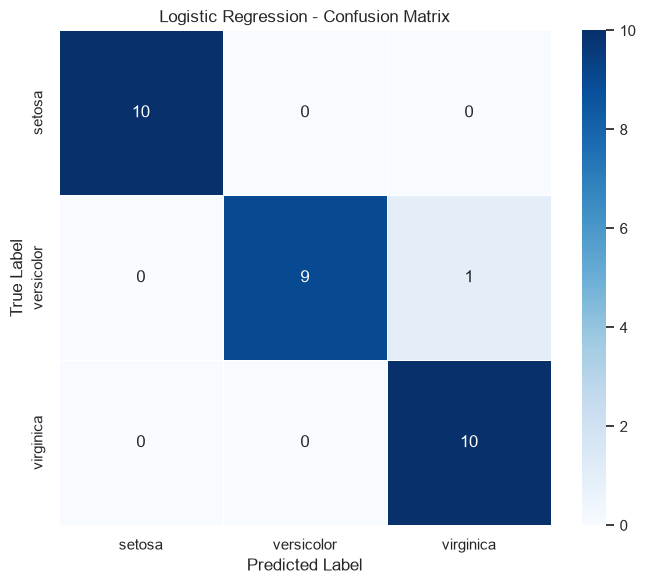

保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\04_iris_logistic_regression_confusion_matrix.png


In [23]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 计算逻辑回归模型的混淆矩阵
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=[0, 1, 2]
)

print("========== 逻辑回归混淆矩阵 ==========")
print(cm_lr)

# 2. 绘制热力图
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    linewidths=0.5
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()

# 3. 保存图片
figure_path = figure_dir / "04_iris_logistic_regression_confusion_matrix.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("保存成功！")
print("保存路径：", figure_path)


========== KNN 混淆矩阵 ==========
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
测试样本总数： 30
预测正确数量： 28
预测错误数量： 2


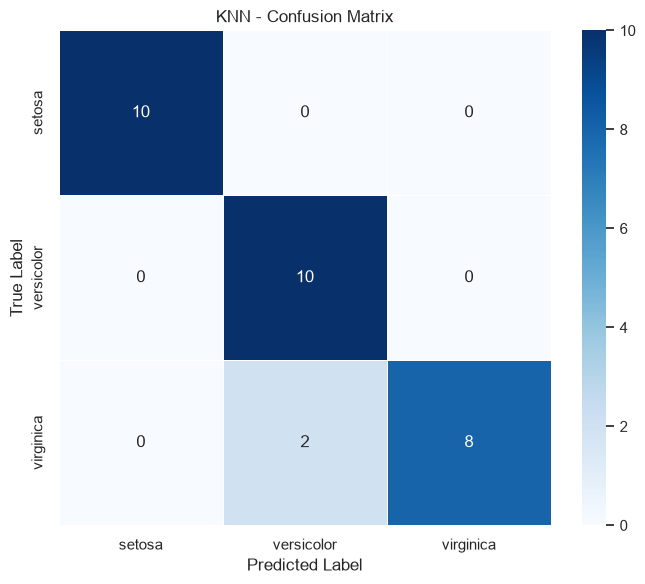

图片保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\05_iris_knn_confusion_matrix.png

========== Decision Tree 混淆矩阵 ==========
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
测试样本总数： 30
预测正确数量： 29
预测错误数量： 1


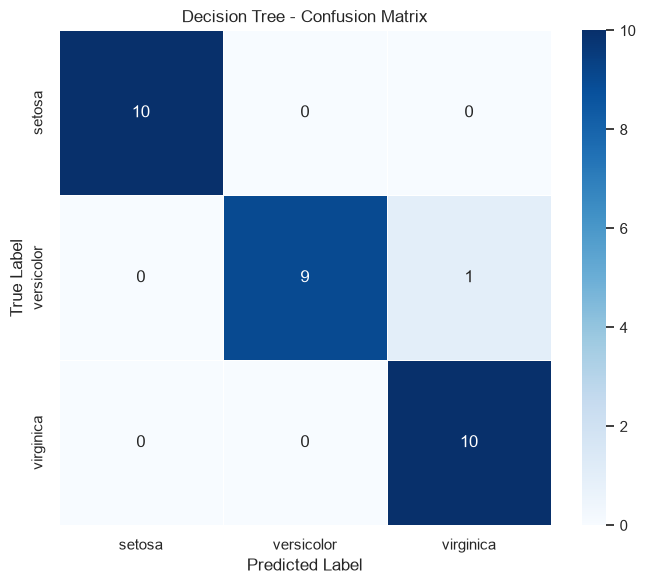

图片保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\06_iris_decision_tree_confusion_matrix.png


In [24]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# KNN 和决策树的混淆矩阵

models_to_plot = [
    {
        "name": "KNN",
        "predictions": y_pred_knn,
        "filename": "05_iris_knn_confusion_matrix.png"
    },
    {
        "name": "Decision Tree",
        "predictions": y_pred_dt,
        "filename": "06_iris_decision_tree_confusion_matrix.png"
    }
]

for model_info in models_to_plot:

    # 1. 计算混淆矩阵
    cm = confusion_matrix(
        y_test,
        model_info["predictions"],
        labels=[0, 1, 2]
    )

    print(f"\n========== {model_info['name']} 混淆矩阵 ==========")
    print(cm)

    # 2. 验证预测结果
    total = cm.sum()
    correct = cm.trace()

    print("测试样本总数：", total)
    print("预测正确数量：", correct)
    print("预测错误数量：", total - correct)

    # 3. 绘制混淆矩阵
    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        linewidths=0.5
    )

    plt.title(f"{model_info['name']} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()

    # 4. 保存图片
    figure_path = figure_dir / model_info["filename"]

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("图片保存成功！")
    print("保存路径：", figure_path)

========== Iris 特征重要性分析 ==========


,Feature,Importance
0,petal length (cm),0.5791
1,petal width (cm),0.4209
2,sepal width (cm),0.0000
3,sepal length (cm),0.0000


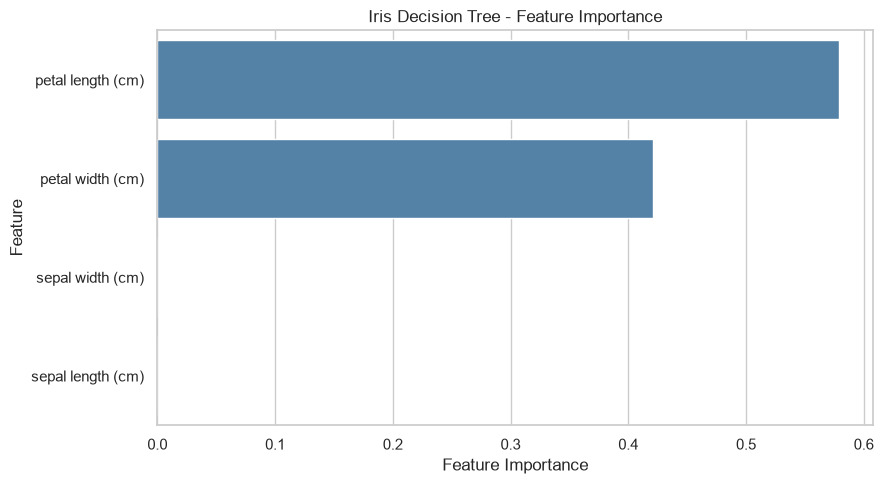

保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\07_iris_feature_importance.png

========== 分析结论 ==========
当前决策树最重要的特征： petal length (cm)
重要性分数：0.5791
四个特征重要性总和：1.0000


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 获取决策树模型的特征重要性
importance_values = dt_model.feature_importances_

# 2. 整理成表格
feature_importance_df = pd.DataFrame({
    "Feature": iris.feature_names,
    "Importance": importance_values
})

# 3. 按重要性从高到低排序
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("========== Iris 特征重要性分析 ==========")
display(feature_importance_df.round(4))

# 4. 绘制特征重要性柱状图
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Iris Decision Tree - Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

# 5. 保存图片
figure_path = figure_dir / "07_iris_feature_importance.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("保存成功！")
print("保存路径：", figure_path)

# 6. 输出最重要的特征
top_feature = feature_importance_df.iloc[0]

print("\n========== 分析结论 ==========")
print("当前决策树最重要的特征：", top_feature["Feature"])
print(f"重要性分数：{top_feature['Importance']:.4f}")
print(f"四个特征重要性总和：{importance_values.sum():.4f}")

In [27]:
from sklearn.inspection import permutation_importance
import pandas as pd

# 三个已经训练好的模型
models = {
    "Logistic Regression": lr_model,
    "KNN": knn_model,
    "Decision Tree": dt_model
}

importance_results = []

# 对三个模型分别计算置换重要性
for model_name, model in models.items():

    result = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="accuracy",
        n_repeats=30,
        random_state=42
    )

    for feature_name, importance in zip(
        iris.feature_names,
        result.importances_mean
    ):
        importance_results.append({
            "Model": model_name,
            "Feature": feature_name,
            "Permutation Importance": importance
        })

# 整理为表格
permutation_df = pd.DataFrame(importance_results)

comparison_table = permutation_df.pivot(
    index="Feature",
    columns="Model",
    values="Permutation Importance"
)

print("========== 三个模型的特征重要性对比 ==========")
display(comparison_table.round(4))

print("\n========== 各模型最重要的特征 ==========")

for model_name in models:
    model_data = permutation_df[
        permutation_df["Model"] == model_name
    ]

    top_feature = model_data.loc[
        model_data["Permutation Importance"].idxmax()
    ]

    print(
        f"{model_name}: "
        f"{top_feature['Feature']} "
        f"({top_feature['Permutation Importance']:.4f})"
    )

========== 三个模型的特征重要性对比 ==========


Model,Decision Tree,KNN,Logistic Regression
Feature,,,
petal length (cm),0.5411,0.2044,0.5789
petal width (cm),0.1489,0.2289,0.1689
sepal length (cm),0.0000,0.0256,0.0089
sepal width (cm),0.0000,0.0067,-0.0022



========== 各模型最重要的特征 ==========
Logistic Regression: petal length (cm) (0.5789)
KNN: petal width (cm) (0.2289)
Decision Tree: petal length (cm) (0.5411)


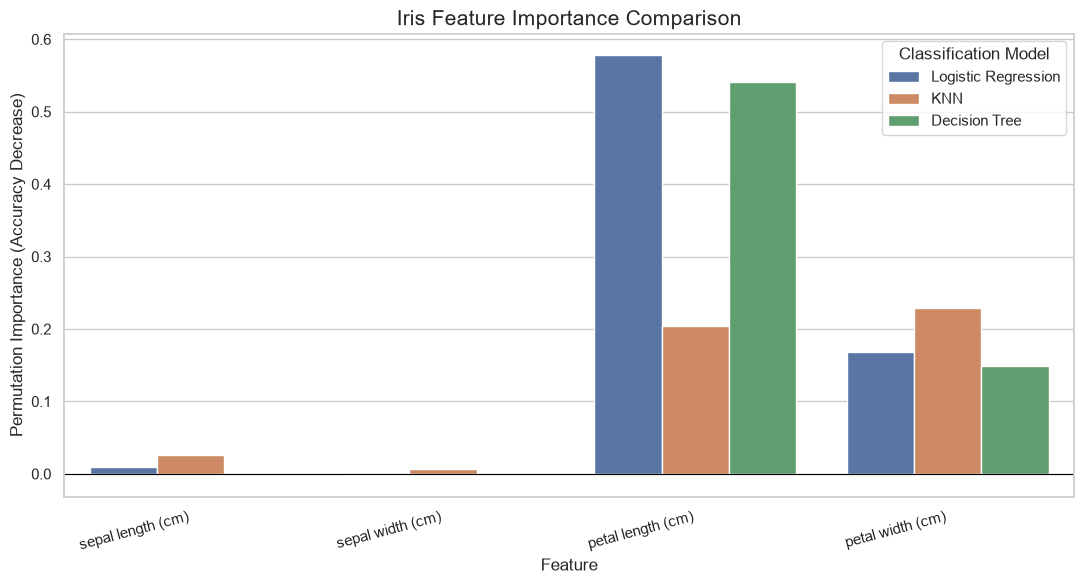

保存成功！
保存路径： D:\AI-Internship\Week01_AI_Basic_Iris_Regression\results\figures\08_iris_model_feature_importance_comparison.png


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 设置绘图样式
sns.set_theme(style="whitegrid")

plt.figure(figsize=(11, 6))

# 2. 绘制分组柱状图
sns.barplot(
    data=permutation_df,
    x="Feature",
    y="Permutation Importance",
    hue="Model",
    errorbar=None
)

# 3. 设置标题和坐标轴
plt.title(
    "Iris Feature Importance Comparison",
    fontsize=15
)
plt.xlabel("Feature")
plt.ylabel("Permutation Importance (Accuracy Decrease)")

# 旋转横轴标签，防止文字重叠
plt.xticks(rotation=15, ha="right")

# 显示零基准线
plt.axhline(y=0, color="black", linewidth=0.8)

plt.legend(title="Classification Model")
plt.tight_layout()

# 4. 保存
figure_path = figure_dir / "08_iris_model_feature_importance_comparison.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("保存成功！")
print("保存路径：", figure_path)